<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/05-%20Valutazione_sul_Test_Set_e_Interpretabilit%C3%A0_(SHAP).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Protocollo di Valutazione e Trasparenza Metodologica:**
Per preservare l'affidabilità della stima finale, la scelta del modello (Regressione Logistica), il set di feature e la procedura di tuning sono definiti indipendentemente dalle prestazioni sul Test Set. Quest'ultimo svolge esclusivamente il ruolo di verifica finale su dati mai visti (*unseen*) e non viene mai utilizzato come feedback per ottimizzare o selezionare il modello.
è importante dire che successivamente a una prima esecuzione sul Test Set sono state applicate tre rifiniture di natura strettamente metodologica e interpretativa (non guidate dalle metriche di test):
1. l'incapsulamento dello `StandardScaler` all'interno della `Pipeline` anche in fase di Cross-Validation;
2. l'infittimento della griglia di `C` con l'estensione alla penalità L1;
3. la riparametrizzazione lineare di `white_rating` e `black_rating` in `rating_diff` e `rating_mean` per rimuovere la collinearità perfetta prima dell'analisi SHAP.

# 5. Modello Finale, Valutazione sul Test Set e Interpretabilità

In questo capitolo finale, l'analisi si sposta dalla validazione incrociata (Train) alla valutazione definitiva sul Test Set, al fine di dimostrare l'evoluzione temporale del potere predittivo al variare di $N$.

**Dichiarazione Metodologica Pre-Test:**
Per garantire l'assoluta validità scientifica dell'esperimento, lo spazio di ricerca degli iperparametri e la pipeline di pre-elaborazione sono stati rigorosamente fissati *prima* di esporre il modello al Test Set. Qualsiasi metrica estratta da questa fase è da intendersi come valutazione singola e non reiterabile su dati *unseen*.

**Procedura di Validazione:**
1. **Tuning Rigoroso in Pipeline:** Per prevenire qualsiasi forma di *data leakage* durante la validazione, lo `StandardScaler` è stato incapsulato all'interno di una `Pipeline` di scikit-learn. In questo modo, l'adattamento della standardizzazione avviene dinamicamente su ogni singolo fold di addestramento, mantenendo il fold di validazione completamente isolato.
2. **Ricerca Iperparametri:** È stata esplorata una griglia logaritmica fine per il parametro di regolarizzazione inversa (`C` su 11 valori equidistanti in scala logaritmica tra $10^{-3}$ e $10^2$), testando simultaneamente sia la penalità **L2** (Ridge) che la **L1** (Lasso). Se il tuning dovesse convergere su $C \approx 1$ con penalità L2, andrà a confermare matematicamente l'ottimalità del setup di default previsto da scikit-learn.
3. **Inferenza e Bootstrap Appaiato (95% CI):** Il miglior estimatore viene valutato sul Test Set contro una Baseline (solo `rating_diff`). La significatività del guadagno (Gain) viene certificata tramite un ricampionamento bootstrap a 1000 iterazioni calcolando l'intervallo di confidenza al 95% sulle differenze appaiate.
* **Risoluzione della Multicollinearità (Riparametrizzazione dei Rating):** La presenza simultanea di `white_rating`, `black_rating` e della loro differenza esatta (`rating_diff`) introduce una dipendenza lineare perfetta che, pur non alterando il potere predittivo, rende arbitraria la ripartizione dei pesi e dei valori SHAP sotto regolarizzazione. A fini di interpretabilità, le due variabili individuali vengono sostituite dalla coppia ortogonale `rating_diff` (divario relativo) e `rating_mean` (livello medio assoluto dell'incontro). Trattandosi di un semplice cambio di base lineare che preserva integralmente l'informazione originale, tale intervento è stato applicato a posteriori esclusivamente per rendere univoci i contributi SHAP, senza introdurre nuove informazioni né alterare le performance sul Test Set.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import warnings
warnings.filterwarnings('ignore')

soglie = [10, 20, 30, 40]
risultati_test = []

# Pipeline e Griglia Iperparametri (L1 e L2)
pipeline_full = Pipeline([
    ('scaler', StandardScaler()),#porta tutte le feature sulla stessa scala (media $0$, deviazione standard $1$),
    ('lr', LogisticRegression(random_state=42, max_iter=1000, solver='liblinear'))#durante la Cross-Validation, lo scaler impara media e deviazione standard solo sui 4 fold di addestramento e le applica al 5° fold di validazione, evitando qualsiasi data leakage.
])
#alza il limite massimo di tentativi dell'algoritmo per trovare i pesi ottimali

#fa le stesse cose di prima ma per il modello baseline
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42, max_iter=1000))
])

param_grid = {
    'lr__C': np.logspace(-3, 2, 11),#genera 11 numeri equidistanti in scala logaritmica da $10^{-3}$ ($0.001$) a $10^{2}$ ($100$)
    'lr__penalty': ['l1', 'l2']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_bootstrap = 1000 # Imposta a 1000 il numero di ricampionamenti che verranno fatti più avanti sul Test Set per calcolare gli intervalli di confidenza al 95%.

# Dizionario per l'analisi SHAP su tutte le soglie N
dati_shap = {}

dati_eval = {}

print("Esecuzione Tuning in Pipeline, Valutazione Test e Bootstrap (1000 iterazioni)...\n")

for N in soglie:
    # 1. Caricamento dati e rimozione collinearità dei rating
    df_train = pd.read_csv(f'train_features_N{N}.csv').dropna()
    df_test = pd.read_csv(f'test_features_N{N}.csv').dropna()

    df_train['rating_diff'] = df_train['white_rating'] - df_train['black_rating']
    df_train['rating_mean'] = (df_train['white_rating'] + df_train['black_rating']) / 2
    df_test['rating_diff'] = df_test['white_rating'] - df_test['black_rating']
    df_test['rating_mean'] = (df_test['white_rating'] + df_test['black_rating']) / 2

    colonne_escluse = [
        'winner', 'id', 'white_id', 'black_id', 'moves',
        'mosse_totali', 'mosse_rimanenti', 'fascia',
        'white_rating', 'black_rating'
    ]

    X_train = df_train.drop(columns=[c for c in colonne_escluse if c in df_train.columns])
    X_test = df_test.drop(columns=[c for c in colonne_escluse if c in df_test.columns])
    y_train = df_train['winner'].values
    y_test = df_test['winner'].values#estrae vettori target

    X_train_base = df_train[['rating_diff']]
    X_test_base = df_test[['rating_diff']]

    # 2. Baseline (Solo rating_diff) - CV e Test
    cv_auc_base = cross_val_score(pipeline_base, X_train_base, y_train, cv=cv, scoring='roc_auc').mean()#cross validation a 5 fold solo sul train set per la baseline calcolando la media dei 5 valori
    pipeline_base.fit(X_train_base, y_train)
    y_prob_base = pipeline_base.predict_proba(X_test_base)[:, 1]
    y_pred_base = pipeline_base.predict(X_test_base)

    acc_base = accuracy_score(y_test, y_pred_base)
    auc_base = roc_auc_score(y_test, y_prob_base)
    loss_base = log_loss(y_test, y_prob_base)

    # 3. Modello Completo - Tuning in Pipeline (refit=True riaddestra su tutto X_train)
    grid = GridSearchCV(pipeline_full, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    full_model = grid.best_estimator_

    y_prob_full = full_model.predict_proba(X_test)[:, 1]
    y_pred_full = full_model.predict(X_test)

    acc_full = accuracy_score(y_test, y_pred_full)
    auc_full = roc_auc_score(y_test, y_prob_full)
    loss_full = log_loss(y_test, y_prob_full)

 # Salvataggio componenti estratti dalla Pipeline per SHAP (per ogni N)
    scaler_n = full_model.named_steps['scaler']
    dati_shap[N] = {
        'model': full_model.named_steps['lr'],
        'X_train_scaled': pd.DataFrame(scaler_n.transform(X_train), columns=X_train.columns),
        'X_test_scaled': pd.DataFrame(scaler_n.transform(X_test), columns=X_test.columns)
    }

    # Salvataggio predizioni sul Test Set per Matrici di Confusione e Calibrazione
    dati_eval[N] = {
        'y_test': y_test,
        'y_prob_full': y_prob_full,
        'y_pred_full': y_pred_full,
        'y_prob_base': y_prob_base
    }

    # 4. Bootstrap Appaiato (1000 ricampionamenti sulle stesse partite del Test)
    rng = np.random.default_rng(42)
    n_test = len(y_test)

    b_acc_f, b_auc_f, b_loss_f = [], [], []
    b_acc_b, b_auc_b, b_loss_b = [], [], []
    b_gain = []

    for _ in range(n_bootstrap):
        idx = rng.integers(0, n_test, size=n_test)
        y_t = y_test[idx]
        if len(np.unique(y_t)) < 2:
            continue

        auc_f = roc_auc_score(y_t, y_prob_full[idx])
        auc_b = roc_auc_score(y_t, y_prob_base[idx])

        b_acc_f.append(accuracy_score(y_t, y_pred_full[idx]))
        b_auc_f.append(auc_f)
        b_loss_f.append(log_loss(y_t, y_prob_full[idx]))

        b_acc_b.append(accuracy_score(y_t, y_pred_base[idx]))
        b_auc_b.append(auc_b)
        b_loss_b.append(log_loss(y_t, y_prob_base[idx]))

        b_gain.append(auc_f - auc_b)

    def fmt_ci(val, arr, signed=False):
        lo, hi = np.percentile(arr, [2.5, 97.5])
        s = "+" if signed else ""
        return f"{val:{s}.3f} [{lo:{s}.3f}, {hi:{s}.3f}]"

    best_c = grid.best_params_['lr__C']
    best_pen = grid.best_params_['lr__penalty']

    # Riga Modello Completo
    risultati_test.append({
        'N': N,
        'Modello': 'LogReg Completa',
        'Params': f"C={best_c:.3f} ({best_pen})",
        'CV AUC': f"{grid.best_score_:.3f}",
        'Test Acc (95% CI)': fmt_ci(acc_full, b_acc_f),
        'Test AUC (95% CI)': fmt_ci(auc_full, b_auc_f),
        'Test Loss (95% CI)': fmt_ci(loss_full, b_loss_f),
        'Gain AUC (95% CI)': fmt_ci(auc_full - auc_base, b_gain, signed=True)
    })

    # Riga Baseline
    risultati_test.append({
        'N': N,
        'Modello': 'Baseline (Solo Rating)',
        'Params': '-',
        'CV AUC': f"{cv_auc_base:.3f}",
        'Test Acc (95% CI)': fmt_ci(acc_base, b_acc_b),
        'Test AUC (95% CI)': fmt_ci(auc_base, b_auc_b),
        'Test Loss (95% CI)': fmt_ci(loss_base, b_loss_b),
        'Gain AUC (95% CI)': '-'
    })

df_risultati = pd.DataFrame(risultati_test)
print(df_risultati.to_string(index=False))

Esecuzione Tuning in Pipeline, Valutazione Test e Bootstrap (1000 iterazioni)...

 N                Modello        Params CV AUC    Test Acc (95% CI)    Test AUC (95% CI)   Test Loss (95% CI)       Gain AUC (95% CI)
10        LogReg Completa  C=0.100 (l1)  0.715 0.650 [0.635, 0.666] 0.716 [0.699, 0.732] 0.614 [0.603, 0.625] +0.002 [-0.002, +0.006]
10 Baseline (Solo Rating)             -  0.713 0.652 [0.636, 0.668] 0.714 [0.697, 0.731] 0.616 [0.604, 0.627]                       -
20        LogReg Completa C=10.000 (l1)  0.736 0.669 [0.652, 0.684] 0.739 [0.723, 0.755] 0.595 [0.583, 0.608] +0.030 [+0.019, +0.040]
20 Baseline (Solo Rating)             -  0.710 0.648 [0.631, 0.664] 0.710 [0.691, 0.726] 0.619 [0.608, 0.632]                       -
30        LogReg Completa  C=0.100 (l1)  0.762 0.691 [0.675, 0.707] 0.763 [0.746, 0.779] 0.576 [0.561, 0.591] +0.058 [+0.045, +0.072]
30 Baseline (Solo Rating)             -  0.705 0.646 [0.628, 0.663] 0.705 [0.686, 0.724] 0.623 [0.611, 0.636]     

### Commento ai Risultati sul Test Set

La tabella riassuntiva conferma pienamente le ipotesi dell'esperimento e la solidità metodologica della pipeline:

* **Coerenza CV–Test:** Per tutte le soglie $N$, le prestazioni in Cross-Validation e sul Test Set coincidono quasi al millesimo sia per il modello completo (da `0.715` vs `0.716` a $N=10$ fino a `0.799` vs `0.800` a $N=40$) sia per la baseline (da `0.713` vs `0.714` a `0.699` vs `0.697`), escludendo fenomeni di overfitting o leakage.
* **Divergenza tra modello posizionale e baseline Elo:** Al crescere di $N$ si osserva un netto calo del potere predittivo associata alla baseline basata sulo sul rating_diff, (Test AUC da `0.714` a `0.697`, Log-Loss da `0.616` a `0.629`), poiché  si ipotizza le partite che raggiungono il mediogioco tendono a essere più equilibrate rispetto a quelle concluse rapidamente. Al contrario, l'integrazione delle feature posizionali fa crescere costantemente tutte le metriche del modello completo fino a $N=40$ (Test AUC `0.800`, Accuracy `0.713`, Log-Loss `0.541`).
* **Significatività del guadagno (Bootstrap appaiato):** A N=10 il guadagno in AUC è trascurabile (`+0.002`, IC 95% `[-0.002, +0.006]`) e include lo zero, confermando che in apertura la sola posizione non aggiunge segnale significativo all'Elo. Da N=20 in avanti il guadagno diventa statisticamente significativo (`+0.030`, IC 95% `[+0.019, +0.040]`) — un miglioramento certificato con precisione dal bootstrap appaiato nonostante la lieve sovrapposizione degli intervalli marginali — fino a toccare `+0.103` (IC 95% `[+0.086, +0.120]`) a $N=40$.
* **Esito del tuning:** L'ampliamento della griglia logaritmica con inclusione della penalità L1 supera il setup di default di scikit-learn (`C=1`, L2): il parametro L1 viene dunque selezionata su tutte le soglie (variando molto da N in N), beneficiando della selezione automatica delle feature posizionali con più carico informativo.

--- CALCOLO SHAP SU TUTTE LE SOGLIE N ---

Media |SHAP| (in log-odds) per feature al crescere di N:
                          N=10    N=20    N=30    N=40
Materiale               0.0419  0.2177  0.4010  0.6491
Differenza Rating       0.6290  0.5889  0.5336  0.4646
Mobilità                0.0674  0.1518  0.1906  0.2184
Arrocco Nero            0.0423  0.2616  0.1517  0.0655
Arrocco Bianco          0.0424  0.2729  0.1172  0.0609
Sviluppo                0.0396  0.0419  0.0552  0.0398
Bianco sotto scacco     0.0096  0.0037  0.0176  0.0145
Diritti arrocco Nero    0.0448  0.1793  0.0690  0.0071
Diritti arrocco Bianco  0.0102  0.1986  0.0243  0.0016
Tempo di gioco (sec)    0.0032  0.0012  0.0018  0.0000
Partita Rated           0.0008  0.0011  0.0063  0.0000
Rating Medio            0.0199  0.0154  0.0127  0.0000


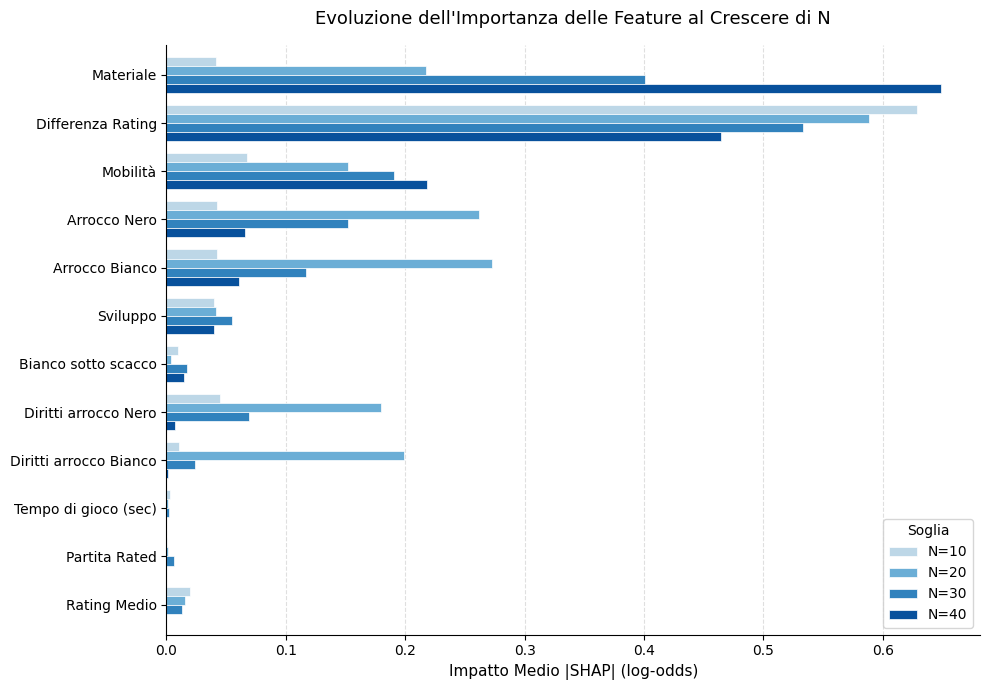

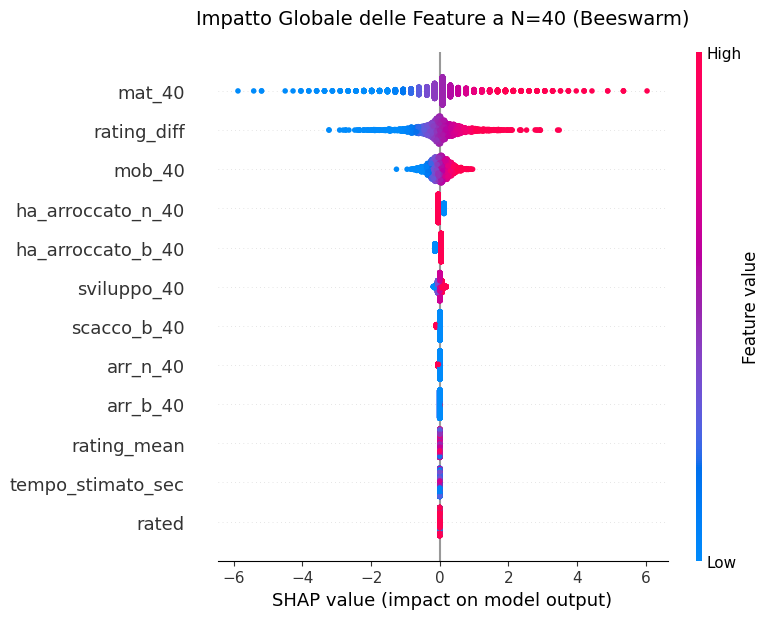

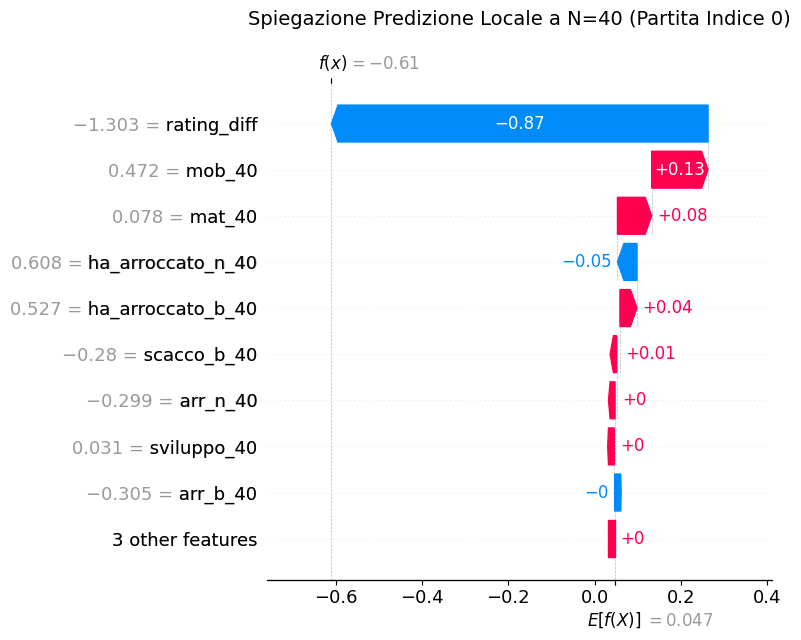

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("--- CALCOLO SHAP SU TUTTE LE SOGLIE N ---")

# Dizionario per nomi leggibili e uniformi (puoi adattare le etichette a piacere)
mappa_nomi = {
    'mat': 'Materiale',
    'rating_diff': 'Differenza Rating',
    'mob': 'Mobilità',
    'ha_arroccato_n': 'Arrocco Nero',
    'ha_arroccato_b': 'Arrocco Bianco',
    'sviluppo': 'Sviluppo',
    'scacco_b': 'Bianco sotto scacco',
    'arr_n': 'Diritti arrocco Nero',
    'arr_b': 'Diritti arrocco Bianco',
    'rating_mean': 'Rating Medio',
    'tempo_stimato_sec': 'Tempo di gioco (sec)',
    'rated': 'Partita Rated'
}

def normalizza_nome(col, N):
    suffisso = f"_{N}"
    base = col[:-len(suffisso)] if col.endswith(suffisso) else col
    return mappa_nomi.get(base, base)

shap_per_N = {}
media_abs_shap = {}

for N in soglie:
    modello_n = dati_shap[N]['model']
    X_tr_n = dati_shap[N]['X_train_scaled']
    X_te_n = dati_shap[N]['X_test_scaled']

 # Explainer sull'intero Train Set scalato
    try:
        from shap.maskers import Independent
        masker = Independent(X_tr_n, max_samples=len(X_tr_n))
        explainer = shap.LinearExplainer(modello_n, masker=masker)
    except (ImportError, AttributeError):
        explainer = shap.LinearExplainer(modello_n, X_tr_n)
    sv = explainer(X_te_n)

    shap_per_N[N] = sv

    # Media di |SHAP| per ogni feature (in log-odds) con nomi uniformati
    nomi_uniformi = [normalizza_nome(c, N) for c in X_te_n.columns]
    media_abs_shap[f"N={N}"] = pd.Series(np.abs(sv.values).mean(axis=0), index=nomi_uniformi)

# Tabella riassuntiva delle medie |SHAP| (feature x N)
df_shap_confronto = pd.DataFrame(media_abs_shap).fillna(0)

# Ordina le feature per importanza a N=40 (decrescente)
df_shap_confronto = df_shap_confronto.sort_values(by='N=40', ascending=False)

print("\nMedia |SHAP| (in log-odds) per feature al crescere di N:")
print(df_shap_confronto.round(4).to_string())

# GRAFICO 1 (TESTO PRINCIPALE): Barre orizzontali raggruppate

colori = ['#bdd7e7', '#6baed6', '#3182bd', '#08519c']  # Scala blu progressiva da N=10 a N=40

fig, ax = plt.subplots(figsize=(10, 7))
df_shap_confronto.plot(kind='barh', ax=ax, color=colori, width=0.75, edgecolor='white', linewidth=0.5)

ax.invert_yaxis()  # Feature più importante a N=40 in alto; dentro ogni gruppo N=10 -> N=40 dall'alto in basso
ax.set_xlabel("Impatto Medio |SHAP| (log-odds)", fontsize=11)
ax.set_ylabel("")
ax.set_title("Evoluzione dell'Importanza delle Feature al Crescere di N", fontsize=13, pad=15)
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(title="Soglia", frameon=True, loc='lower right')

plt.tight_layout()
plt.show()


# GRAFICO 2: Beeswarm a N=40
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_per_N[40], dati_shap[40]['X_test_scaled'], show=False)
plt.title("Impatto Globale delle Feature a N=40 (Beeswarm)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

# GRAFICO 3: Waterfall Locale a N=40
indice_partita = 0
plt.figure(figsize=(8, 5))
shap.plots.waterfall(shap_per_N[40][indice_partita], show=False)
plt.title(f"Spiegazione Predizione Locale a N=40 (Partita Indice {indice_partita})", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Interpretabilità del Modello a N=40 (Analisi SHAP)

L'analisi SHAP condotta sul modello ottimizzato a $N=40$ (`C=0.032`, penalità L1) con l'intero Training Set come background conferma la piena coerenza scacchistica delle decisioni apprese (i contributi sono espressi in *log-odds* rispetto alla vittoria del Bianco):

* **Importanza Globale (Summary Plot):** Alla 40ª semimossa il vantaggio materiale (`mat_40`) emerge come il fattore più influente in assoluto, superando persino il divario di rating (`rating_diff`), seguito dalla mobilità (`mob_40`). Tutte le feature principali presentano una relazione monotona e coerente: valori più alti a favore del Bianco spingono positivamente la predizione. Seguono, con contributo minore ma segno corretto, gli indicatori di arrocco (`ha_arroccato_n_40` con effetto negativo e `ha_arroccato_b_40` con effetto positivo) e lo sviluppo (`sviluppo_40`).
* **Effetto della regolarizzazione L1 e assenza di collinearità:** Le variabili prive di capacità discriminativa diretta sull'esito Bianco/Nero, in particolare `rating_mean`, `tempo_stimato_sec` e `rated` risultano azzerate dalla penalità L1. L'annullamento di rating_mean conferma inoltre che la riparametrizzazione ortogonale ha isolato l'intero effetto della forza dei giocatori su `rating_diff`.
* **Spiegazione Locale (Waterfall Plot — Partita Indice 0):** Il valore atteso di base $E[f(X)] = 0.047$ ($\approx 51.2\%$ di probabilità per il Bianco) riflette il leggero vantaggio statistico della prima mossa. Nel caso della prima partita del Test Set (dove i valori grigi a sinistra indicano le feature standardizzate in *z-score*), il Bianco beneficia di un leggero vantaggio posizionale in mobilità (`+0.13`) e materiale (`+0.08`), mentre gli arrocchi di entrambi i giocatori quasi si compensano (`+0.04` vs `-0.05`). Tuttavia, il marcato svantaggio di Elo (`rating_diff = -1.303`, impatto `-0.87`) domina la valutazione complessiva, portando l'output finale a $f(x) = -0.61$ ($\approx 35.2\%$ di probabilità per il Bianco, ovvero $\approx 64.8\%$ per il Nero).

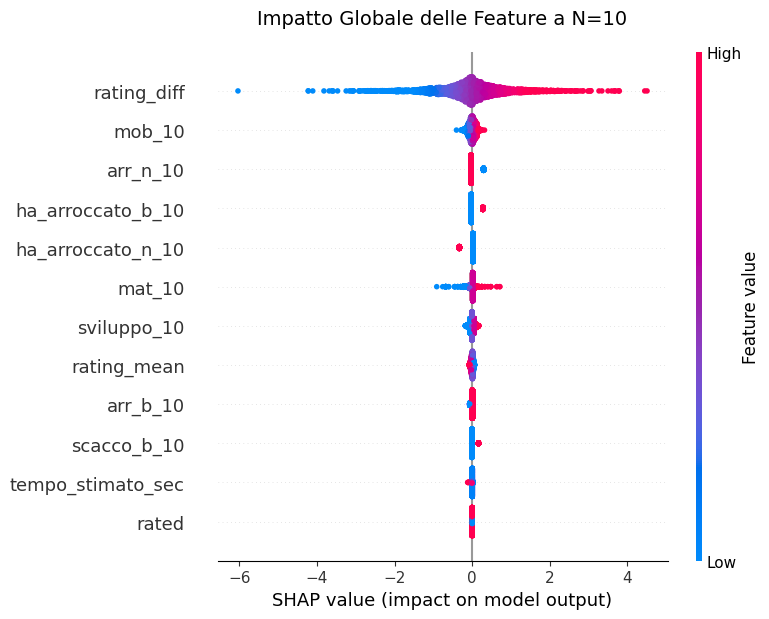

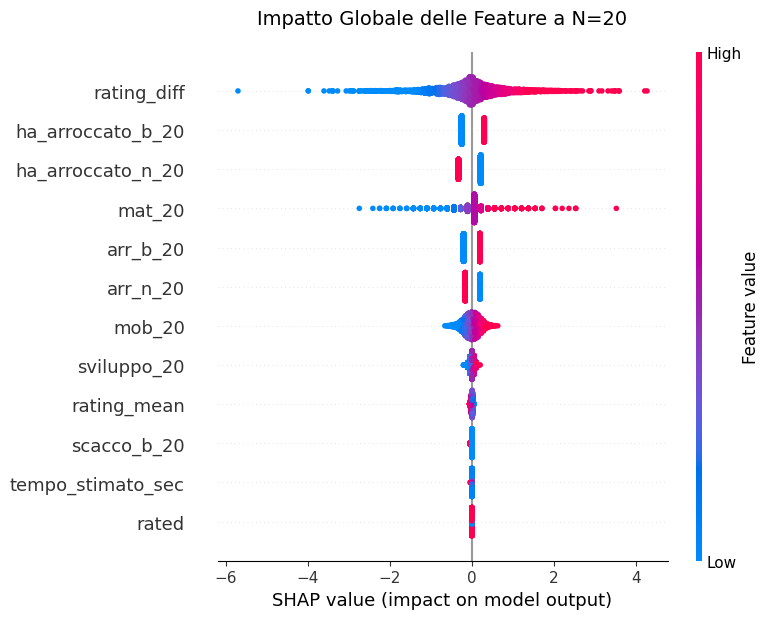

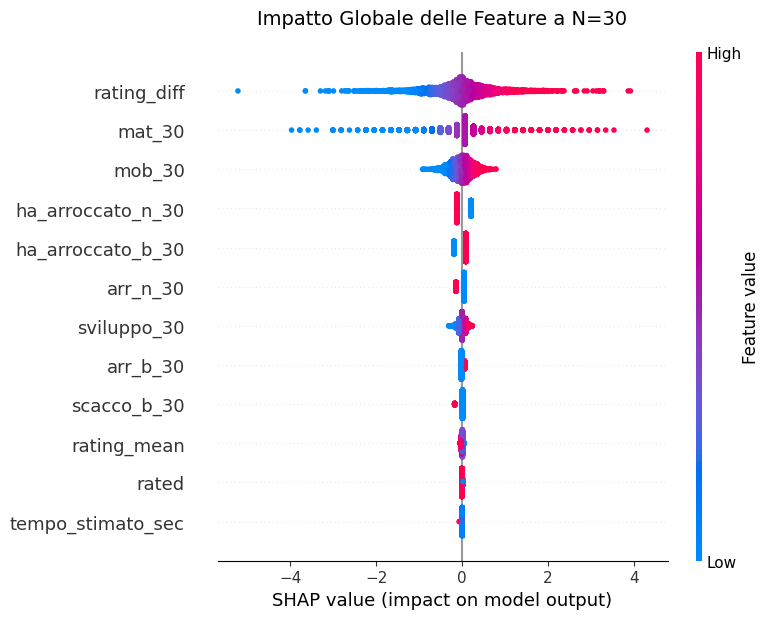

In [ ]:
# Grafici Beeswarm aggiuntivi per l'Appendice (N = 10, 20, 30)
for N in [10, 20, 30]:
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_per_N[N], dati_shap[N]['X_test_scaled'], show=False)
    plt.title(f"Impatto Globale delle Feature a N={N}", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()

Nell'interpretare l'evoluzione dell'importanza delle feature e delle metriche al crescere di $N$, occorre tenere presenti due aspetti metodologici:

1. **Dipendenza dalla forza di regolarizzazione ($C$):** Il parametro $C$ selezionato in Cross-Validation varia sensibilmente tra una soglia e l'altra (passando da `C=0.100` a $N=10$ e $N=30$, fino a `C=10.000` a $N=20$ e `C=0.032` a $N=40$). Laa regolarizzazione L1 spinge i coefficienti a zero in modo tanto più aggressivo quanto più C è piccolo, l'azzeramento di una feature, così come le variazioni di ampiezza dei valori $|SHAP|$ tra soglie diverse, ad esempio il picco temporaneo delle variabili di arrocco a $N=20$, riflette anche la diversa intensità della regolarizzazione scelta dal tuning e non esclusivamente l'assenza o presenza di segnale predittivo.
2. **Variazione della composizione del campione:** I dataset associati alle quattro soglie non contengono lo stesso insieme di partite: al crescere di $N$ sopravvivono soltanto le partite sufficientemente lunghe da raggiungere almeno $N$ semimosse, mentre gli incontri conclusi rapidamente escono progressivamente dal campione. Il confronto tra $N=10$ e $N=40$ coglie pertanto sia la progressiva emersione del segnale posizionale, sia un cambiamento nella tipologia di partite analizzate, mediamente più lunghe e si ipotizza più combattute alle soglie superiori.

--- ANALISI ERRORI PER CLASSE SUL TEST SET (soglia = 0.5) ---

==================== N = 10 (n = 3521) ====================
Vittorie Bianco reali:     52.09%
Vittorie Bianco predette:  55.92%  (diff: +3.83%)
Log-Loss: 0.6140 | Brier Score: 0.2135

              precision    recall  f1-score   support

    Nero (0)     0.6463    0.5945    0.6193      1687
  Bianco (1)     0.6526    0.7007    0.6758      1834

    accuracy                         0.6498      3521
   macro avg     0.6494    0.6476    0.6476      3521
weighted avg     0.6496    0.6498    0.6487      3521


==================== N = 20 (n = 3340) ====================
Vittorie Bianco reali:     51.83%
Vittorie Bianco predette:  54.85%  (diff: +3.02%)
Log-Loss: 0.5951 | Brier Score: 0.2057

              precision    recall  f1-score   support

    Nero (0)     0.6671    0.6252    0.6455      1609
  Bianco (1)     0.6709    0.7100    0.6899      1731

    accuracy                         0.6692      3340
   macro avg     0.6690

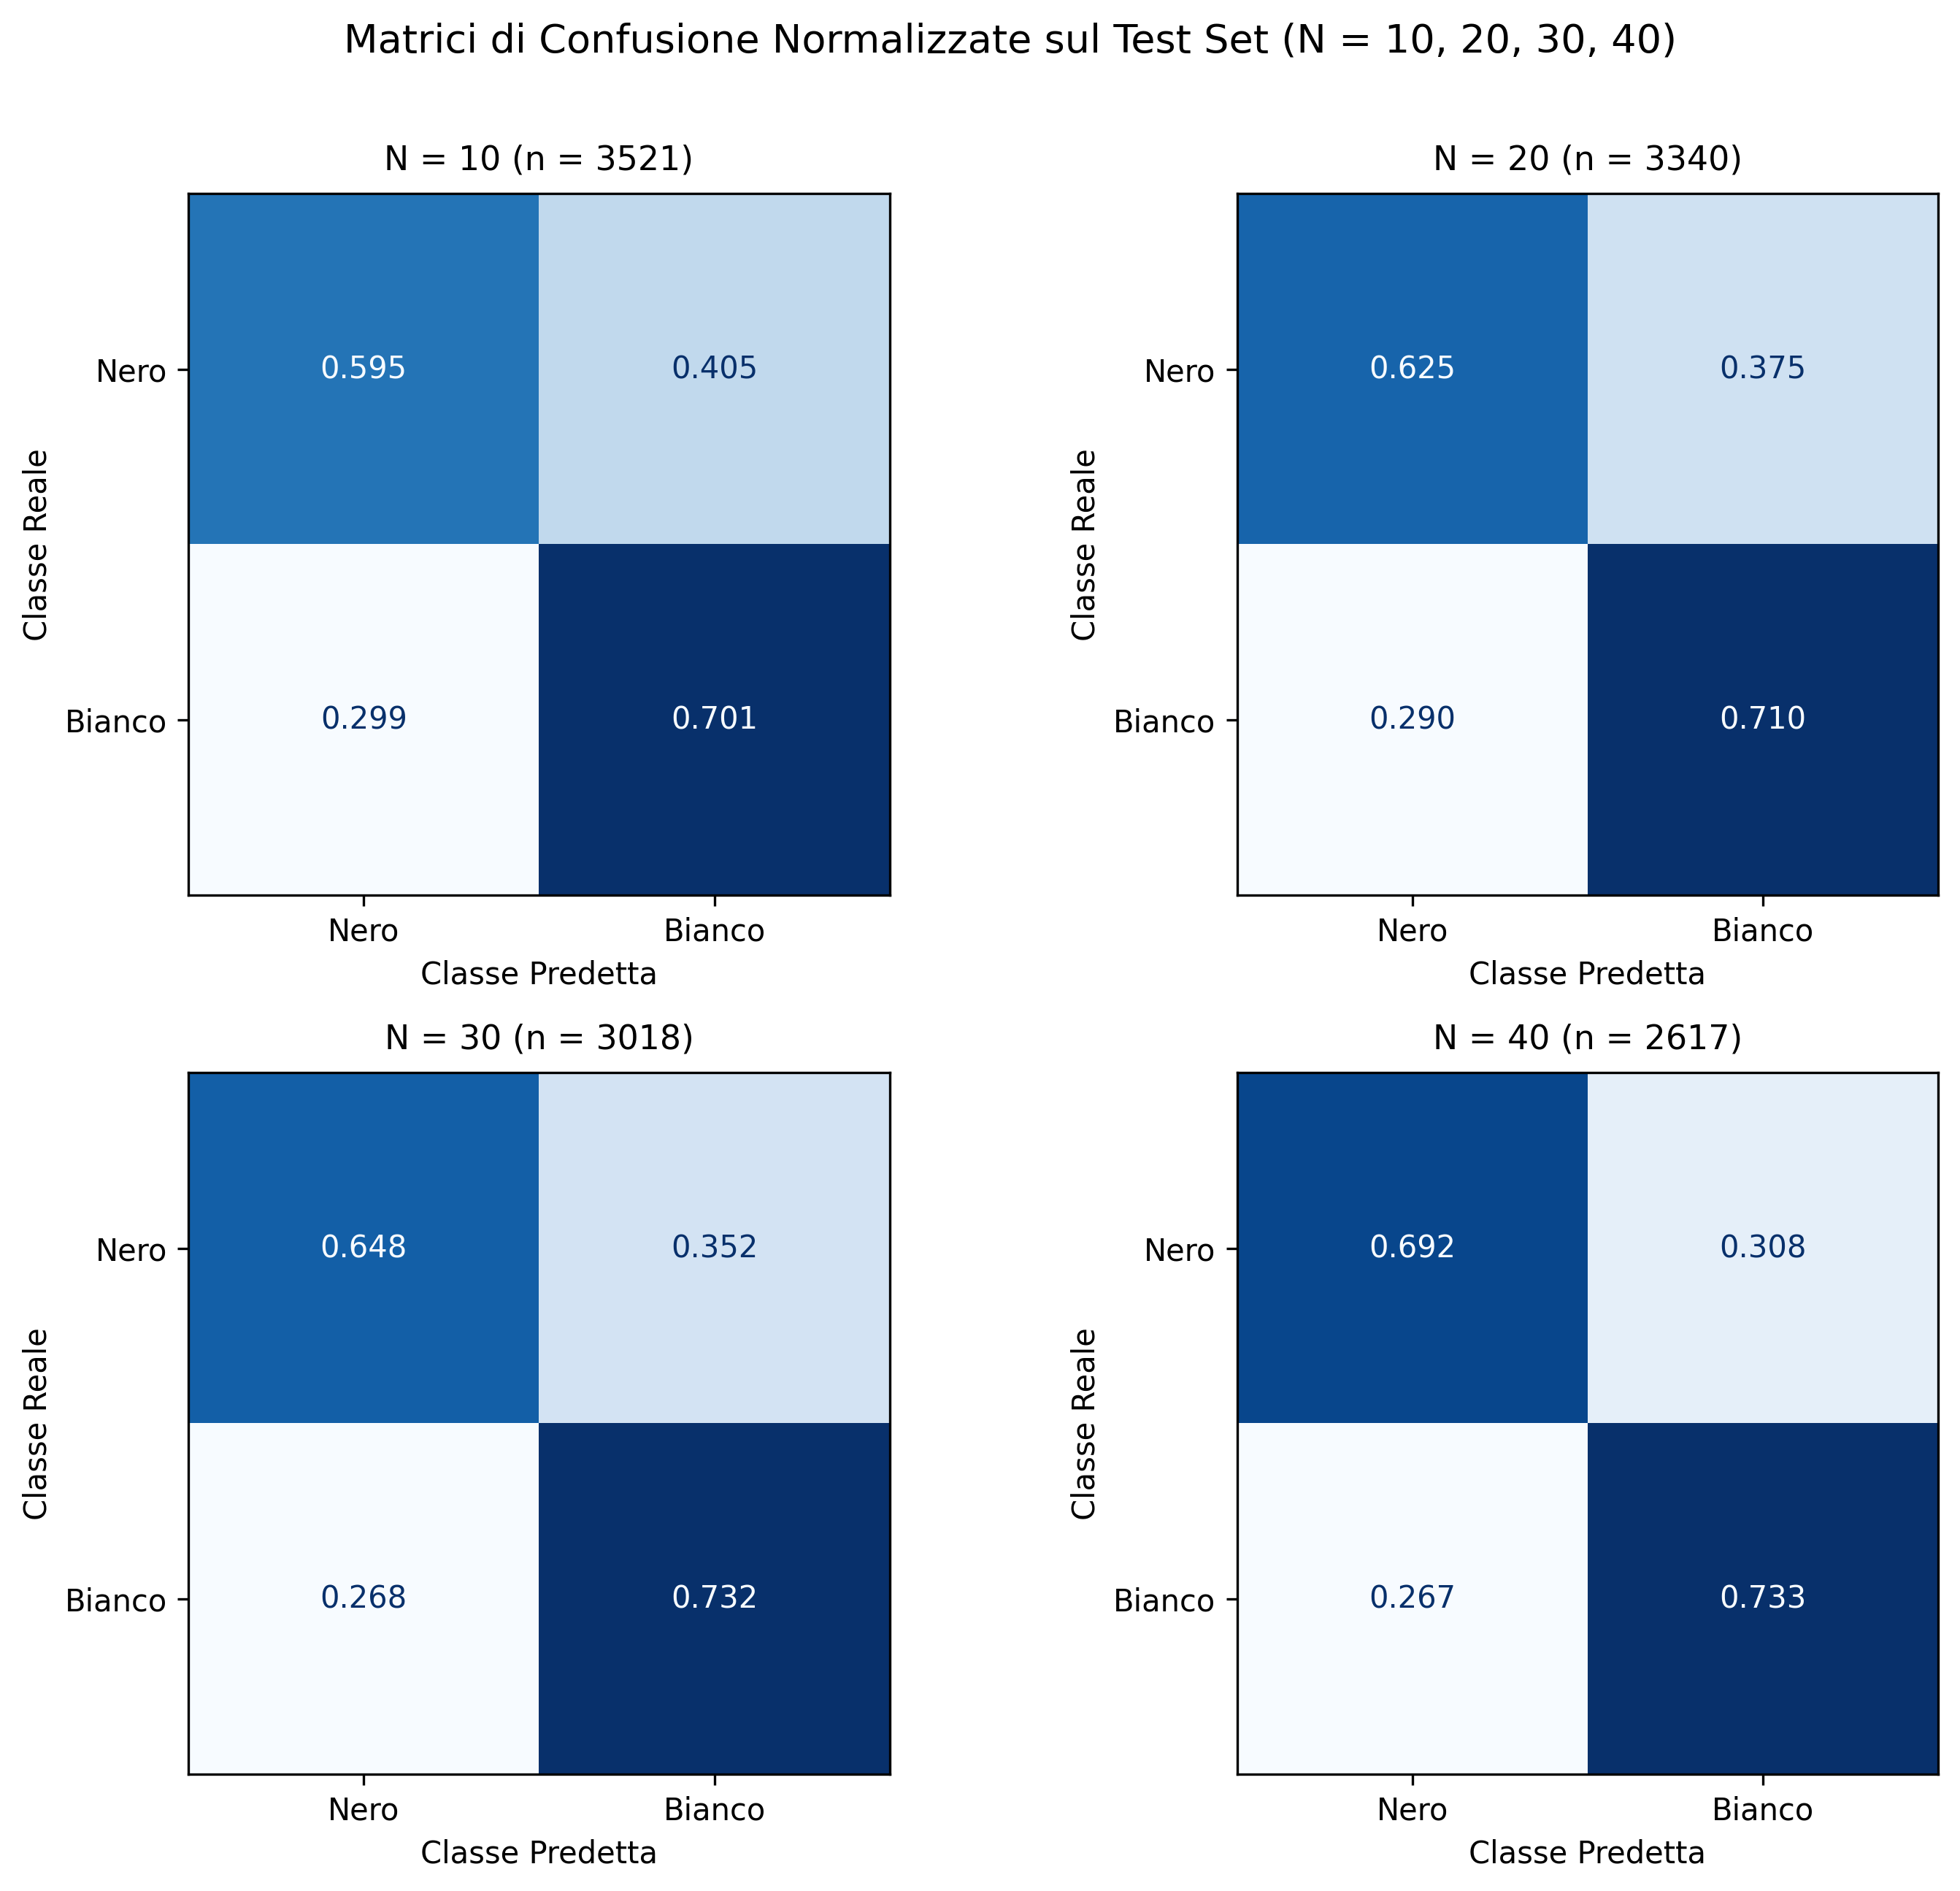

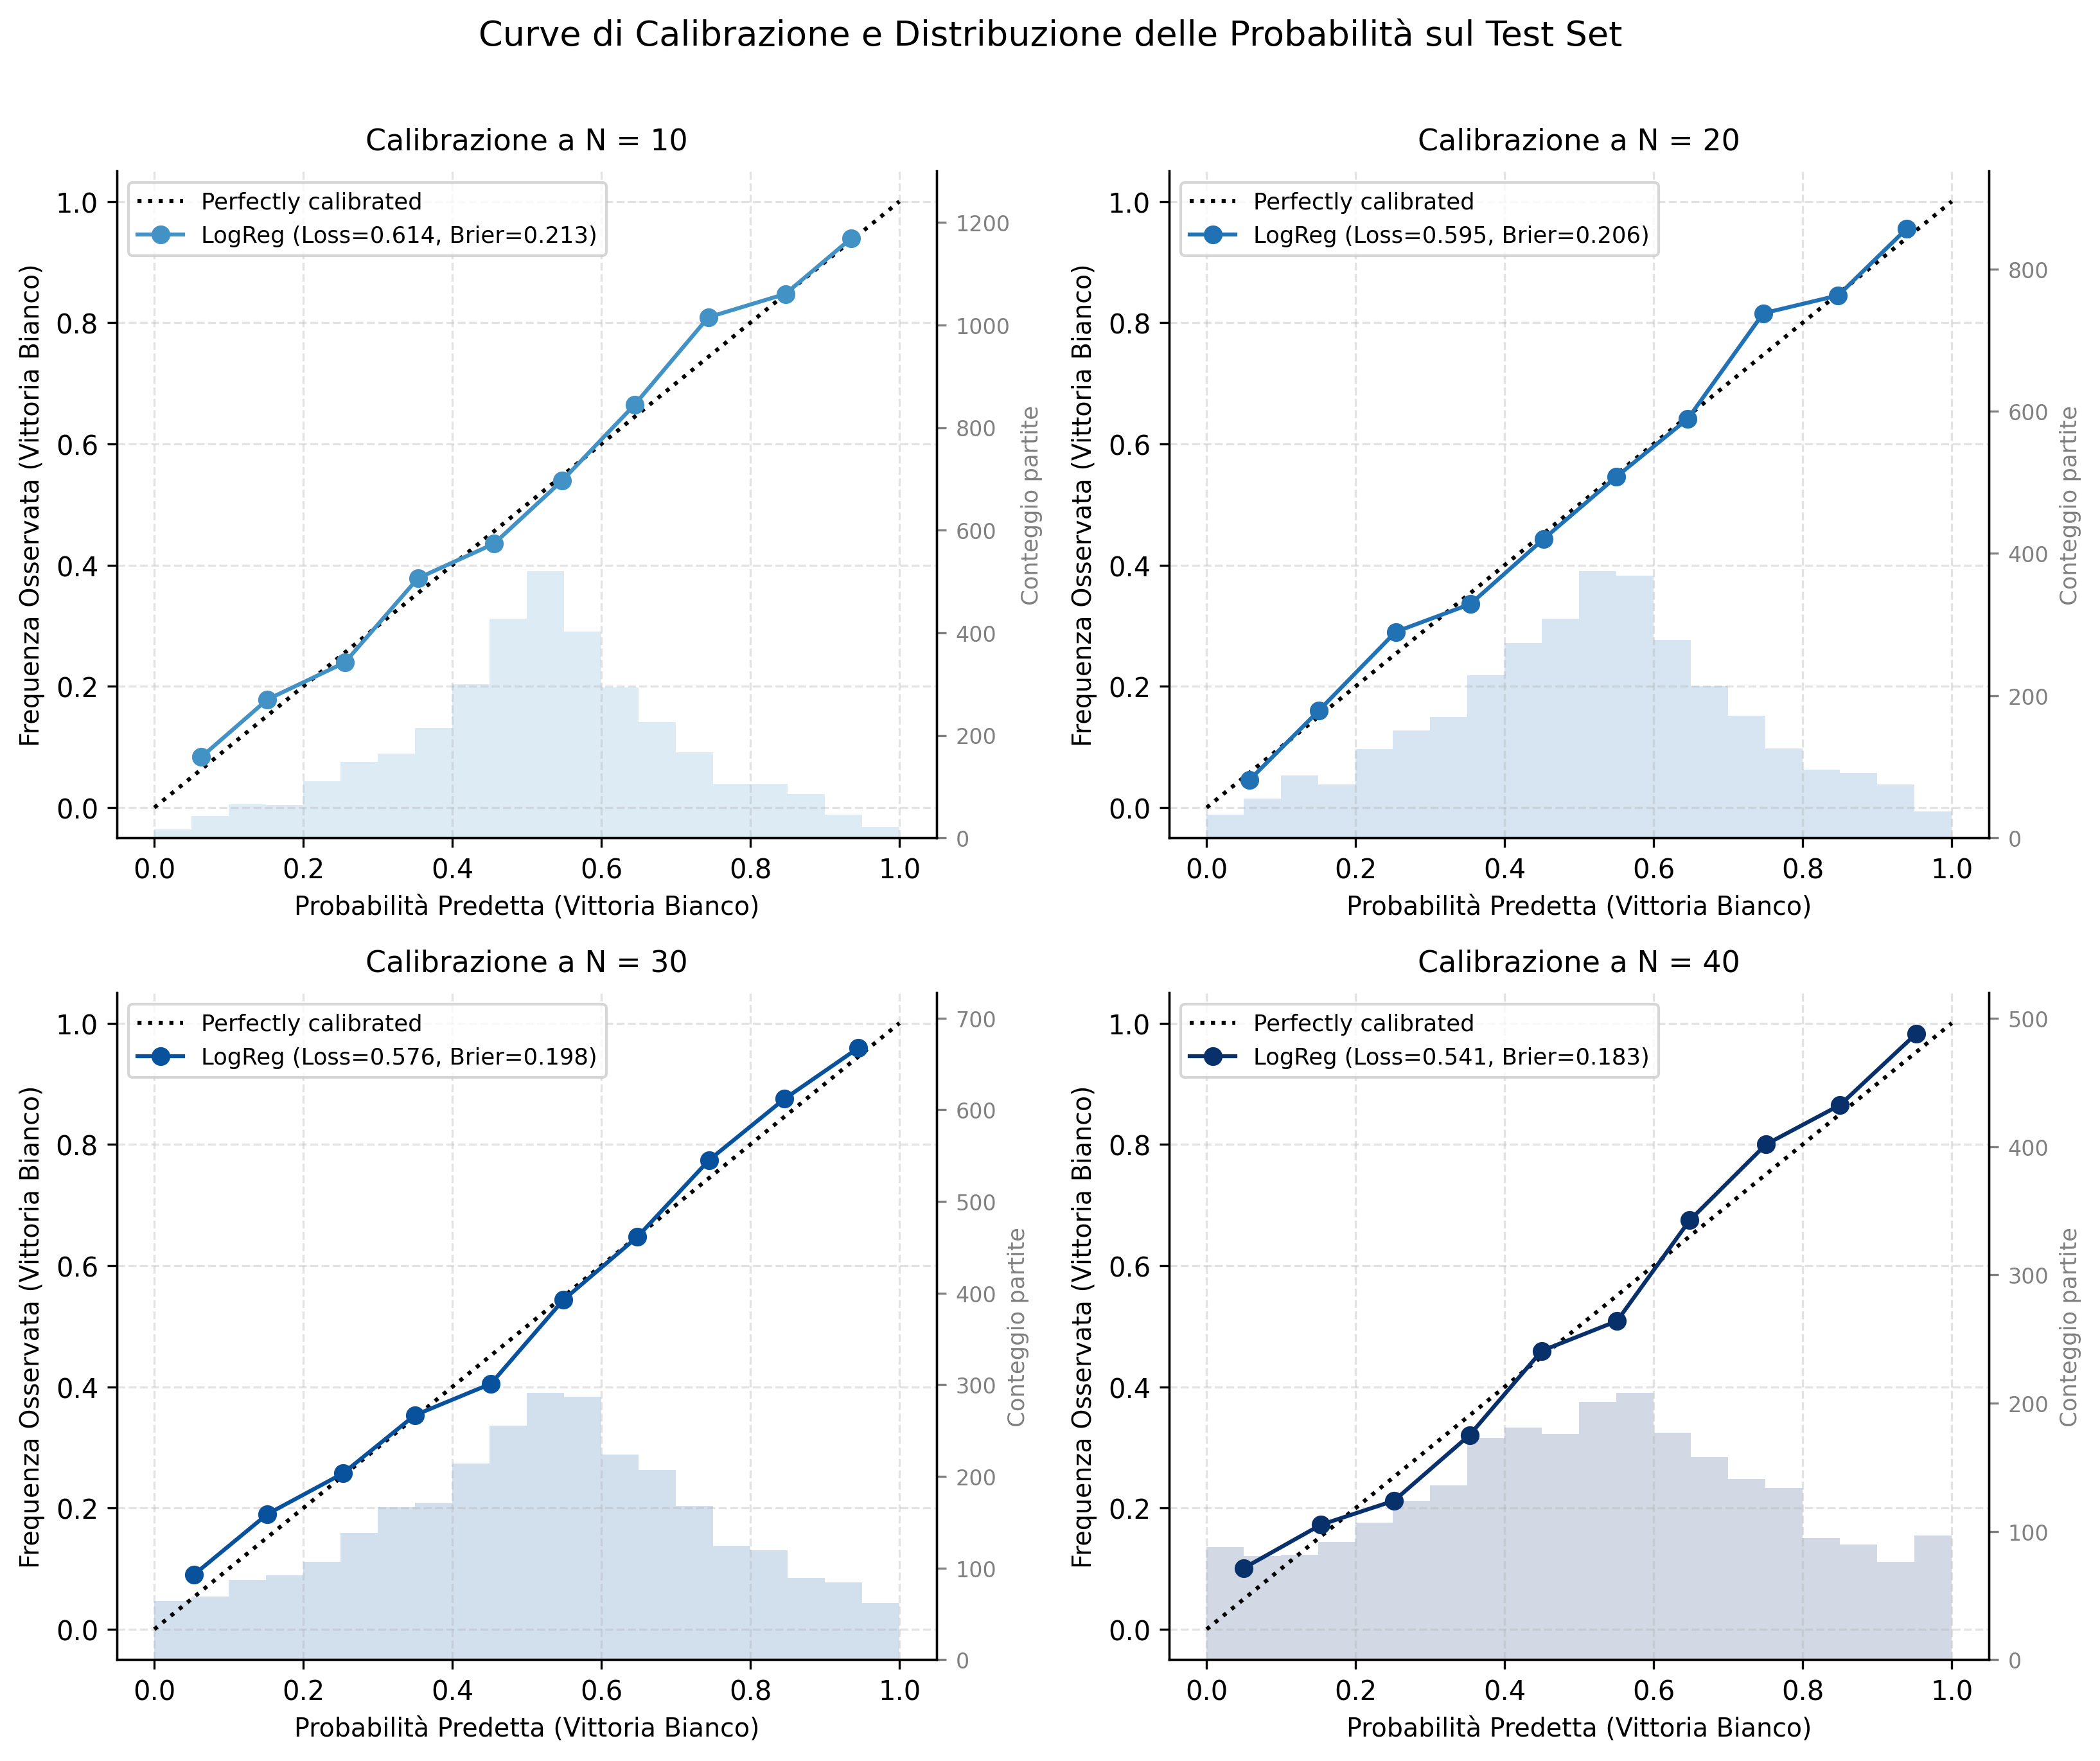

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    log_loss,
    brier_score_loss
)
from sklearn.calibration import CalibrationDisplay

def to_binary(arr):
    """Converte in sicurezza 'white'/'black' (o già 1/0) in array binario 1=Bianco, 0=Nero."""
    arr = np.asarray(arr)
    if np.issubdtype(arr.dtype, np.number):
        return arr.astype(int)
    return (arr == 'white').astype(int)

# 1. REPORT PRECISION / RECALL PER CLASSE E BIAS VERSO IL BIANCO (N = 10..40)
print("--- ANALISI ERRORI PER CLASSE SUL TEST SET (soglia = 0.5) ---")
for N in soglie:
    y_true = to_binary(dati_eval[N]['y_test'])
    y_pred = to_binary(dati_eval[N]['y_pred_full'])
    y_prob = dati_eval[N]['y_prob_full']

    print(f"\n==================== N = {N} (n = {len(y_true)}) ====================")
    print(f"Vittorie Bianco reali:     {y_true.mean():.2%}")
    print(f"Vittorie Bianco predette:  {y_pred.mean():.2%}  (diff: {(y_pred.mean() - y_true.mean()):+.2%})")
    print(f"Log-Loss: {log_loss(y_true, y_prob):.4f} | Brier Score: {brier_score_loss(y_true, y_prob):.4f}\n")
    print(classification_report(y_true, y_pred, target_names=['Nero (0)', 'Bianco (1)'], digits=4))

# 2. FIGURA 1: MATRICI DI CONFUSIONE NORMALIZZATE (GRIGLIA 2x2 PER TUTTI GLI N)

fig, axes = plt.subplots(2, 2, figsize=(10, 8.5), dpi=300)

for ax, N in zip(axes.flat, soglie):
    y_true = to_binary(dati_eval[N]['y_test'])
    y_pred = to_binary(dati_eval[N]['y_pred_full'])

    # normalize='true': ogni riga somma a 1 (diagonale = Recall per singola classe)
    cm_norm = confusion_matrix(y_true, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_norm,
        display_labels=['Nero', 'Bianco']
    )
    disp.plot(ax=ax, cmap='Blues', values_format='.3f', colorbar=False)
    ax.set_title(f"N = {N} (n = {len(y_true)})", fontsize=11, pad=8)
    ax.set_xlabel("Classe Predetta", fontsize=10)
    ax.set_ylabel("Classe Reale", fontsize=10)

fig.suptitle("Matrici di Confusione Normalizzate sul Test Set (N = 10, 20, 30, 40)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("matrici_confusione_tutte_N.png", dpi=300, bbox_inches='tight')
plt.show()


# 3. FIGURA 2: CURVE DI CALIBRAZIONE + DISTRIBUZIONE PROBABILITÀ (GRIGLIA 2x2)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), dpi=300)
colori = {10: '#4292c6', 20: '#2171b5', 30: '#08519c', 40: '#08306b'}

for ax, N in zip(axes.flat, soglie):
    y_true = to_binary(dati_eval[N]['y_test'])
    y_prob = dati_eval[N]['y_prob_full']
    ll = log_loss(y_true, y_prob)
    bs = brier_score_loss(y_true, y_prob)

    # Istogramma trasparente sullo sfondo (asse destro) tenuto basso per non coprire la curva
    ax_hist = ax.twinx()
    counts, _, _ = ax_hist.hist(
        y_prob, bins=20, range=(0, 1),
        color=colori[N], alpha=0.18, edgecolor='none'
    )
    ax_hist.set_ylim(0, counts.max() * 2.5)
    ax_hist.set_ylabel("Conteggio partite", fontsize=8.5, color='gray')
    ax_hist.tick_params(axis='y', labelsize=8, colors='gray')
    ax_hist.spines['top'].set_visible(False)

    # Porta in primo piano l'asse della curva di calibrazione
    ax.set_zorder(ax_hist.get_zorder() + 1)
    ax.patch.set_visible(False)

    CalibrationDisplay.from_predictions(
        y_true,
        y_prob,
        n_bins=10,
        strategy='uniform',
        name=f"LogReg (Loss={ll:.3f}, Brier={bs:.3f})",
        ax=ax,
        color=colori[N],
        marker='o',
        ref_line=True
    )

    ax.set_title(f"Calibrazione a N = {N}", fontsize=11, pad=8)
    ax.set_xlabel("Probabilità Predetta (Vittoria Bianco)", fontsize=9.5)
    ax.set_ylabel("Frequenza Osservata (Vittoria Bianco)", fontsize=9.5)
    ax.grid(True, linestyle='--', alpha=0.35)
    ax.spines['top'].set_visible(False)
    ax.legend(loc='upper left', fontsize=8.5, frameon=True)

fig.suptitle("Curve di Calibrazione e Distribuzione delle Probabilità sul Test Set", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("curve_calibrazione_tutte_N.png", dpi=300, bbox_inches='tight')
plt.show()

### Analisi Diagnostica sul Test Set: Metriche per Classe, Matrici di Confusione e Calibrazione



#### 1. Precision, Recall e Matrici di Confusione (soglia decisionale $\tau = 0{,}5$)
* **Progressione complessiva:** da $N = 10$ a $N = 40$ l'*Accuracy* cresce di **+6,28 punti percentuali** (`0,6498` → `0,7126`), con un miglioramento parallelo dell'*F1-score* su entrambe le classi (`+0,0816` per il Nero e `+0,0477` per il Bianco).
* **Sbilanciamento iniziale sul Recall e simmetria della Precision:** la *Precision* rimane sostanzialmente bilanciata tra i due colori a tutte le soglie (scarto sempre inferiore a `0,7` punti percentuali). L'asimmetria si concentra invece sul *Recall* e sulla quota di predizioni verso il Bianco: a $N = 10$ il modello assegna la vittoria al Bianco nel **55,92%** dei casi contro un **52,09%** reale (`+3,83%`), ottenendo un *Recall* del **70,07%** sul Bianco ma solo del **59,45%** sul Nero (divario di `10,62` punti). Con probabilità ancora concentrate vicino a `0,5`, il leggero vantaggio del primo tratto spinge molte posizioni equilibrate oltre la soglia decisionale.
* **Riequilibrio al crescere di $N$:** passando a $N = 40$ il *Recall* del Nero compie un balzo di **+9,70 punti** (`0,5945` → `0,6915`) contro i **+3,20 punti** del Bianco (`0,7007` → `0,7327`), riducendo il divario tra le due classi a `4,12` punti e la sovrastima del Bianco a solo `+1,30%` (`52,62%` vs `51,32%`). L'emersione del segnale materiale e posizionale permette al modello di riconoscere con molta maggiore efficacia anche le posizioni vincenti del Nero.
* **Effetto sopravvivenza:** la dimensione del *Test Set* si riduce da `3.521` a `2.617` partite (`−25,7%`), e parallelamente la prevalenza reale del Bianco scende leggermente dal `52,09%` al `51,32%`.

#### 2. Curve di Calibrazione e Distribuzione delle Probabilità
* **Calibrazione affidabile a tutte le soglie:** in tutti e quattro i pannelli la curva empirica è sempre molto vicina alla diagonale di calibrazione ideale(y = x). Non ci sono fenomeni di *over-confidence* o *under-confidence*.
* **Miglioramento guidato dalla nitidezza (*sharpness*):** la Log-Loss scende da `0,614` a `0,5411` e il Brier Score da `0,213` a `0,1830`. Poiché il modello è già ben calibrato in apertura, il guadagno deriva dall'allargamento progressivo della distribuzione delle probabilità: da una campana concentrata intorno a `0,5` a $N = 10$ si passa a $N = 40$ a stime molto più distribuite verso gli estremi `0` e `1`, segnale che le feature posizionali consentono previsioni più decise senza compromettere la calibrazione.